In [1]:
#
# WE START BY REBUILDING EVERYTHING FROM Finance.ipynb
#

import pandas as pd
import pandas_datareader as web
import matplotlib.pyplot as plt
%matplotlib inline
import yfinance as yf
import pprint
start_date = pd.to_datetime('2020-01-01')
end_date = pd.to_datetime('2025-01-01')
apple_df1 = pd.DataFrame(web.DataReader('AAPL', 'stooq', start_date, end_date)[::-1]['Close'], columns=['Close']) 
cisco_df1 = pd.DataFrame(web.DataReader('CSCO', 'stooq', start_date, end_date)[::-1]['Close'], columns=['Close'])
IBM_df1 = pd.DataFrame(web.DataReader('IBM', 'stooq', start_date, end_date) [::-1]['Close'], columns=['Close'])
AMAZON_df1 = pd.DataFrame(web.DataReader('AMZN', 'stooq', start_date, end_date) [::-1]['Close'], columns=['Close'])

money_invested = 10000
for stock_df,allo in zip([ apple_df1 ,cisco_df1, IBM_df1, AMAZON_df1 ], [ .3, .2, .4, .1 ]):
    stock_df['Normed Return'] = stock_df['Close'] / stock_df.iloc[0]['Close']
    stock_df['Allocation'] = stock_df['Normed Return'] * allo
    stock_df['Position'] = stock_df['Allocation'] * money_invested
# 

all_positions = [ x['Position'] for x in [ apple_df1 ,cisco_df1, IBM_df1, AMAZON_df1 ] ]
#
# important to specify the Y axis as the axis
portfolio_df = pd.concat(all_positions, axis = 1)
portfolio_df.columns = ['AAPL Position', 'CSCO Position','IBM Position','AMAZN Position', ]
#
# Note the axis is 1 because I run the df in vertical
portfolio_df['Total'] = portfolio_df.sum(axis=1)
portfolio_df.head()

,AAPL Position,CSCO Position,IBM Position,AMAZN Position,Total
Date,,,,,
2020-01-02,3000.000000,2000.000000,4000.000000,1000.000000,10000.000000
2020-01-03,2970.930784,1967.369011,3967.923235,987.860970,9894.084001
2020-01-06,2994.430394,1974.402212,3960.555175,1002.565845,9931.953626
2020-01-07,2980.489878,1961.538029,3963.536669,1004.662778,9910.227354
2020-01-08,3028.388486,1962.816792,3996.675805,996.817720,9984.698803


Portfolio Mean: 0.0007682837807381918
Portfolio STD: 0.014902344838962918
Portfolio Cumulative Return (%): 128.3103305869547


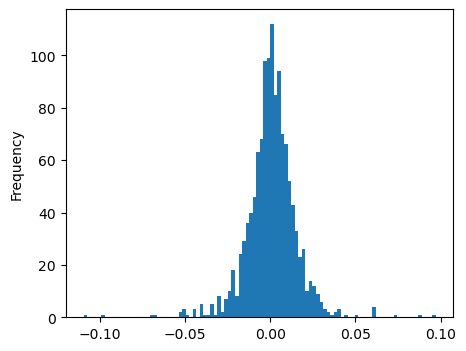

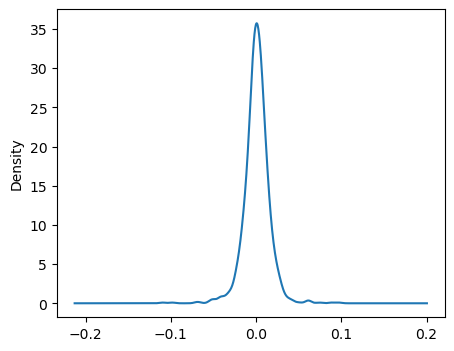

In [2]:
#
# Adding now some other stats:
# - Daily Percentage return
#
# then we get the mean and standard deviation and we plot it  


portfolio_df['Daily Return'] = portfolio_df['Total'].pct_change(1)
portfolio_mean = portfolio_df['Daily Return'].mean()
portfolio_std = portfolio_df['Daily Return'].std()
cumulative_return = ((portfolio_df.iloc[-1]['Total'] / portfolio_df.iloc[0]['Total']) - 1 ) * 100
print(f"Portfolio Mean: {portfolio_mean}")
print(f"Portfolio STD: {portfolio_std}")
print(f"Portfolio Cumulative Return (%): {cumulative_return}")
portfolio_df['Daily Return'].plot(kind='hist', bins=100, figsize=(5,4))
plt.show()
portfolio_df['Daily Return'].plot(kind='kde', figsize=(5,4))
plt.show()


In [3]:
portfolio_df.iloc[0]['Total']

np.float64(10000.0)

In [5]:
#
# SHARPE RATIO
#
from math import sqrt
# Note that 
#  - we assume R_f is == 0
#  - To get the annual sharpe ration:
#       - Mean_yearly == Mean_Daily   
#       - the variance will be V_yearly = sqrt(N) * V_unit
#.        Brcause we have dayly units and 255 working days V_yearly  / sqrt(255) = V_unit
#
risk_free_return = 0
SR = portfolio_mean / portfolio_std 
ASR = SR * sqrt(255)
print(f"The portfolio Sharpe Ratio (daily) is : {SR} and the Annual SHarpe Ratio is : {ASR}") 
#
# Generally speking 
#   - a ratio higher than 1 is considered good
#   - a ratio higher than 2 is considered very good
#   - a ratio higher than 3 is conisdered exceptionally good

The portfolio Sharpe Ratio (daily) is : 0.051554556617793186 and the Annual SHarpe Ratio is : 0.8232602495897618


In [ ]:
#
# How do we optimize the best portfolio allocation?
#  - we can use numpy/pandas power to test different allocations and plot them 
#    and get the best allocation (based on sharpe ratio)
#
#  - we can try to use math to fund the optimal allocation (minimization/maximization problem)
#    we will use scypy for this 
#
# 

In [6]:
#
# Method 1
# what we do is to create a graph with Volatility as X axis and Return as Y axis
# A 3 dimension is added by color to show the sharpe ratio value
# The figure will have an upper border which shows the maximum return you can have (Y value)
# for a specific volatility/X (Risk value)
# Anything below the border is then probably a bad choice because you could do better
#
# The border is called Fisher Frontier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plot
import pandas_datareader as web
%matplotlib inline
start_date = pd.to_datetime('2025-01-01')
end_date = pd.to_datetime('2025-12-01')
aapl   = pd.DataFrame(web.DataReader('AAPL', 'stooq', start_date, end_date)[::-1]['Close'], columns=['Close']) 
csco   = pd.DataFrame(web.DataReader('CSCO', 'stooq', start_date, end_date)[::-1]['Close'], columns=['Close'])
ibm    = pd.DataFrame(web.DataReader('IBM', 'stooq', start_date, end_date) [::-1]['Close'], columns=['Close'])
amzn   = pd.DataFrame(web.DataReader('AMZN', 'stooq', start_date, end_date) [::-1]['Close'], columns=['Close'])
stocks = pd.concat([aapl,csco,ibm,amzn], axis = 1)
columns = ['AAPL', 'CSCO', 'IBM', 'AMZN']
stocks.columns = columns
stocks.head()

,AAPL,CSCO,IBM,AMZN
Date,,,,
2025-01-02,243.582,59.10,219.94,220.22
2025-01-03,243.093,58.86,222.65,224.19
2025-01-06,244.731,58.77,222.67,227.61
2025-01-07,241.944,58.93,223.96,222.11
2025-01-08,242.433,59.20,223.18,222.13


In [7]:
#
# just to show one more thing..
# we can get the daily percentage return and find the correlation between the different stocks
# if we do something like
#
# Note that of course, each stcok is perfectly correlated with each other.. hence the 1 value on th diagonal
stocks.pct_change(1).corr()

,AAPL,CSCO,IBM,AMZN
AAPL,1.000000,0.542375,0.357970,0.572283
CSCO,0.542375,1.000000,0.383107,0.462918
IBM,0.357970,0.383107,1.000000,0.225201
AMZN,0.572283,0.462918,0.225201,1.000000


In [8]:
#
# FROM NOW ON WE USE LOG RETURNs instead of Arithmentic Returns
# Most of the times, the result is basically the same however..
# Working with logs tends to normalize the time series
#
# example below
# Arithmetic Returns
import pprint
print("------ Arithmetic Daily Percentage values")
pprint.pprint(stocks.pct_change(1).head())

stocks_log_values = np.log(stocks / stocks.shift(1))
print("------ Logarithmic Daily Percentage values")
pprint.pprint(stocks_log_values.head())

------ Arithmetic Daily Percentage values
                AAPL      CSCO       IBM      AMZN
Date                                              
2025-01-02       NaN       NaN       NaN       NaN
2025-01-03 -0.002008 -0.004061  0.012322  0.018027
2025-01-06  0.006738 -0.001529  0.000090  0.015255
2025-01-07 -0.011388  0.002722  0.005793 -0.024164
2025-01-08  0.002021  0.004582 -0.003483  0.000090
------ Logarithmic Daily Percentage values
                AAPL      CSCO       IBM      AMZN
Date                                              
2025-01-02       NaN       NaN       NaN       NaN
2025-01-03 -0.002010 -0.004069  0.012246  0.017867
2025-01-06  0.006716 -0.001530  0.000090  0.015140
2025-01-07 -0.011453  0.002719  0.005777 -0.024461
2025-01-08  0.002019  0.004571 -0.003489  0.000090


array([[<Axes: title={'center': 'AAPL'}>,
        <Axes: title={'center': 'CSCO'}>],
       [<Axes: title={'center': 'IBM'}>,
        <Axes: title={'center': 'AMZN'}>]], dtype=object)

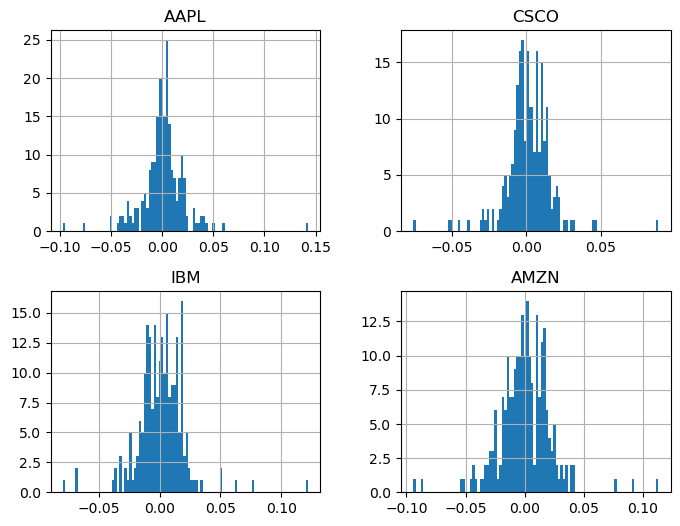

In [9]:
stocks_log_values.hist(bins=100,figsize=(8,6))


In [11]:
#
#
# now we can get correlation and covariance of the stocks
print(f"--------\n Log Correlation is : \n{stocks_log_values.corr()}")
print(f"--------\n Log Covariance  is : \n{stocks_log_values.cov()}")
print("")

--------
 Log Correlation is : 
          AAPL      CSCO       IBM      AMZN
AAPL  1.000000  0.538907  0.359968  0.569681
CSCO  0.538907  1.000000  0.383203  0.461921
IBM   0.359968  0.383203  1.000000  0.226566
AMZN  0.569681  0.461921  0.226566  1.000000
--------
 Log Covariance  is : 
          AAPL      CSCO       IBM      AMZN
AAPL  0.000443  0.000175  0.000148  0.000268
CSCO  0.000175  0.000239  0.000116  0.000160
IBM   0.000148  0.000116  0.000384  0.000099
AMZN  0.000268  0.000160  0.000099  0.000501



In [12]:
#
# NOW WE
# - RUN A FIRST ROUND OF RANDOM ALLOCATION
# - CREATE A FOR LOOP WITH RANDOM VALUES
#
# Having the seed in the same cell, you will always get the same value
# It's going to be different though if you call the random in a different cell
np.random.seed(101)
weights = np.array(np.random.random(4)) 
weights = weights / np.sum(weights)
print(f"Our weights are: {weights} and their sum is : {np.sum(weights)}")

Our weights are: [0.40122278 0.44338777 0.02212343 0.13326603] and their sum is : 1.0000000000000002


In [14]:
# The expected return is given by:
#   mean of the Daily Percentage Change  *  # of days  * weight
# 
# So
exp_return = stocks_log_values.mean() * weights * 252
total_exp_return = np.sum(exp_return)
print(f"\n-------------\nExpected return: \n{exp_return} - Total {total_exp_return}") 
#
# Now, to get the expected volatility..
# The formula does not really change but to make the code faster
# we are going to use some numpy optimization code:
#  - step1: covariance matrix (variance in the diagonal) * 252 days * weights)
#  - step2: dot product the result for the weights again
#  - step3: take the square root --> this leaves sqrt(252) * sqrt(varince) * weights
exp_volatility = np.sqrt(np.dot(weights.T, np.dot(stocks_log_values.cov()*252, weights)))
print(f"\n-------------\nThe expected volatility is : {exp_volatility}")
#
#
# Now we can get the Sharpe Ratio (annual as we have adjusted the values)
SR = exp_volatility / exp_return
print(f"\n-------------\nThe SR is : {exp_volatility}")


-------------
Expected return: 
AAPL    0.066672
CSCO    0.123509
IBM     0.008048
AMZN    0.008864
dtype: float64 - Total 0.20709416264978345

-------------
The expected volatility is : 0.24737125638679305

-------------
The SR is : 0.24737125638679305


In [17]:
#
# MONTE CARLO SIMULATION
# Now we take teh process above and repeat it 5K times..
np.random.seed(101)
num_iterations = 25000
all_weights    = np.zeros((num_iterations,len(stocks.columns)))
weights        = np.random.random(4)
weights        = weights / sum(weights) 
sharpe_array   = np.zeros(num_iterations)
vol_array      = np.zeros(num_iterations)
returns_array  = np.zeros(num_iterations)

for idx in range(num_iterations):
    weights             = np.random.random(4)
    weights             = weights / sum(weights)  
    # save the weights
    all_weights[idx, :] = weights  
    # 
    returns_array[idx]  = np.sum(stocks_log_values.mean() * weights * 252 )
    #
    vol_array[idx]      = np.sqrt(np.dot(weights.T, np.dot(stocks_log_values.cov()*252, weights)))
    #
    sharpe_array[idx]   = returns_array[idx] / vol_array[idx]



-----------
The max vlue for sharpe index is: 1.3796623507839803 at location 23556
The optimal allocation weights are  [0.00087624 0.5757253  0.41600646 0.007392  ]
-----------


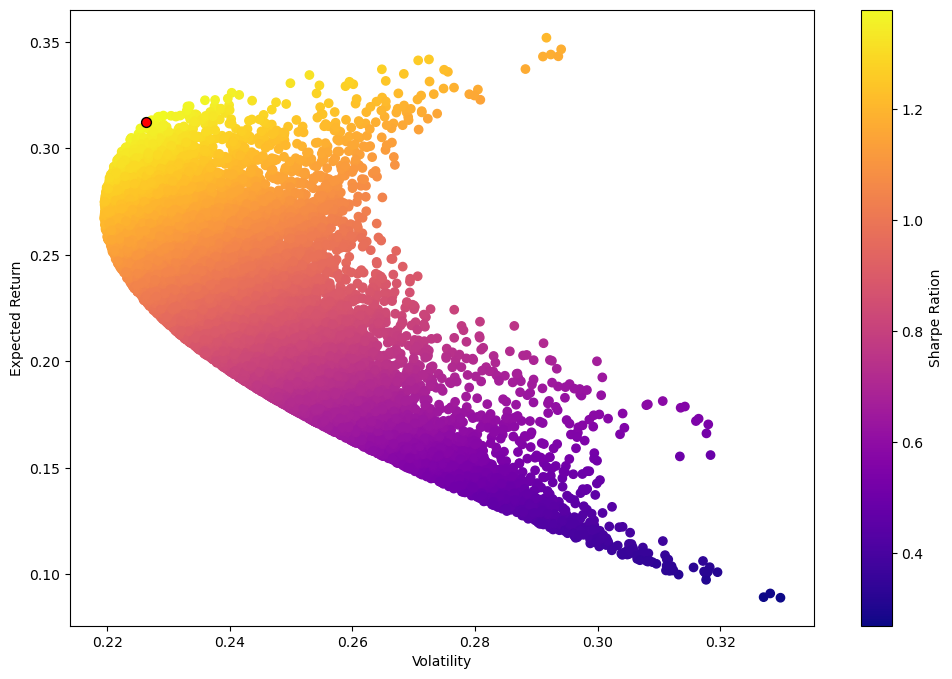

In [26]:
print("-----------")
print(f"The max vlue for sharpe index is: {sharpe_array.max()} at location {sharpe_array.argmax()}")
print(f"The optimal allocation weights are  {all_weights[ sharpe_array.argmax() ]}")
print("-----------")
plt.figure(figsize=(12,8))
plt.scatter(vol_array, returns_array, c=sharpe_array, cmap='plasma')
plt.colorbar(label='Sharpe Ration')
plt.xlabel('Volatility')
plt.ylabel('Expected Return')

max_sr_ret = returns_array[ sharpe_array.argmax() ]
max_sr_volatility = vol_array[ sharpe_array.argmax() ]
plt.scatter(max_sr_volatility, max_sr_ret, c='red',s=50, edgecolors='black')


In [ ]:
#
# The Border line in the picture represents the fisher Frontier
# it represents the max return you can get for a specific risk (i.e. volatility)
# Ther red dot gives us the maximum value we can get for sharpe ratio
# which is gives in turn the best combination of the weights for the stock protfolio


In [33]:
#
#
# MATHEMATICAL APPROACH
#
# Here we use scipy.optimize
from scipy.optimize import minimize

In [40]:
def get_ret_vol_sr(weights):
    weights = np.array(weights)

    ret = np.sum(stocks_log_values.mean() * weights * 252 )
    #
    vol  = np.sqrt(np.dot(weights.T, np.dot(stocks_log_values.cov()*252, weights)))
    #
    sharpe_ratio = ret / vol
    #
    return np.array([ret, vol, sharpe_ratio])

#
# Because we want optimize by finding a minimum
# but the best sharpe ratio is the maximum, we invert it
# so that we can use the minimize function
def neg_sharpe(weights):
    return get_ret_vol_sr(weights)[2] * -1

#
# 
# ####################### CONSTRAINTS
# Adding  constraints help to minimize the search space
#
# 1. Returns 0 if the sum of the weights == 1
def check_sum(weights):
    return np.sum(weights) -1

#
#
######################## CONTRAINTS MAP
# This is where we keep track of what contraints we apply
# each one is mapped to a function
# Note that this format and keys are fixed as they are required by the minimize function
constraints = (
    {'type':'eq', 'fun': check_sum }
)


#
#
##################### BOUNDS
# This defines the bounds of each of the weight (i.e. 0 and 1 for each weight)
bounds = ( (0,1), (0,1), (0,1), (0,1) )    

#
#
################## INITIAL GUESS
# This is the starting point.. as we don't have any reason to use different values for 
# the different weights, we start with all equal weights
init_gues = [0.25, 0.25, 0.25, 0.25]

In [41]:
#
# MIMINIZE
#
# Here we call the minimize scipy function giving as paramters:
# - the function we want to minimize: neg_sharpe
# - the initial values
# - method: there are different solvers available.. see documentation
#           here we use SLSQP (again check docs..)
#           Sequential Least Square
# - bounds
# - contraints
opt_results = minimize(neg_sharpe, 
                       init_gues, 
                       method='SLSQP',
                       bounds = bounds,
                       constraints = constraints
                       )

opt_results

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -1.3864686682894622
           x: [ 1.463e-16  5.422e-01  4.578e-01  0.000e+00]
         nit: 5
         jac: [ 3.602e-01 -6.576e-04  7.787e-04  5.890e-01]
        nfev: 25
        njev: 5
 multipliers: [-2.020e-05]

In [ ]:
#
#
# The optimization results are from the x value
print("-------")
print(f"Optimizal minimization results are for  {opt_results.x}")
print("-------")
print(f"which give a SR of {get_ret_vol_sr(opt_results.x)[2]}")
#
# Note that this is better than what we got from Monte Carlo simulation (but close)

-------
Optimizal minimization results are for  [1.46343339e-16 5.42183338e-01 4.57816662e-01 0.00000000e+00]
-------
which give a SR of 1.3864686682894622


In [53]:
#
#
# FISHER FRONTIER
#
# Defines the optimum portfolio for a defined value of Risk (or the lowest risk possible for a desired return)
# In the example below, we try to minimize the volatility while we know that return is between 0 0.4 (so we create
# 100 points and map them to the minimal volatility we can get)
#
frontier_volatility = []
frontier_y = np.linspace(0, 0.4, 100)

#
# this is the function that we want to minimize (it returns volatility)
def minimize_volatility(weights):
    return get_ret_vol_sr(weights)[1]



for possible_return in frontier_y:
    constraints = (
        {'type':'eq', 'fun': check_sum },
        #
        # this contraint means that for a specific set of weights
        # we get the return and subtract the possible return (that comes from the forniter_y)
        { 'type':'eq', 'fun': lambda w: get_ret_vol_sr(w)[0] - possible_return },
     )
    result = minimize(minimize_volatility, init_gues, method='SLSQP', bounds=bounds, constraints=constraints)
    #
    # result.fun is the result of the minimization function (see example above)
    frontier_volatility.append(result['fun'])

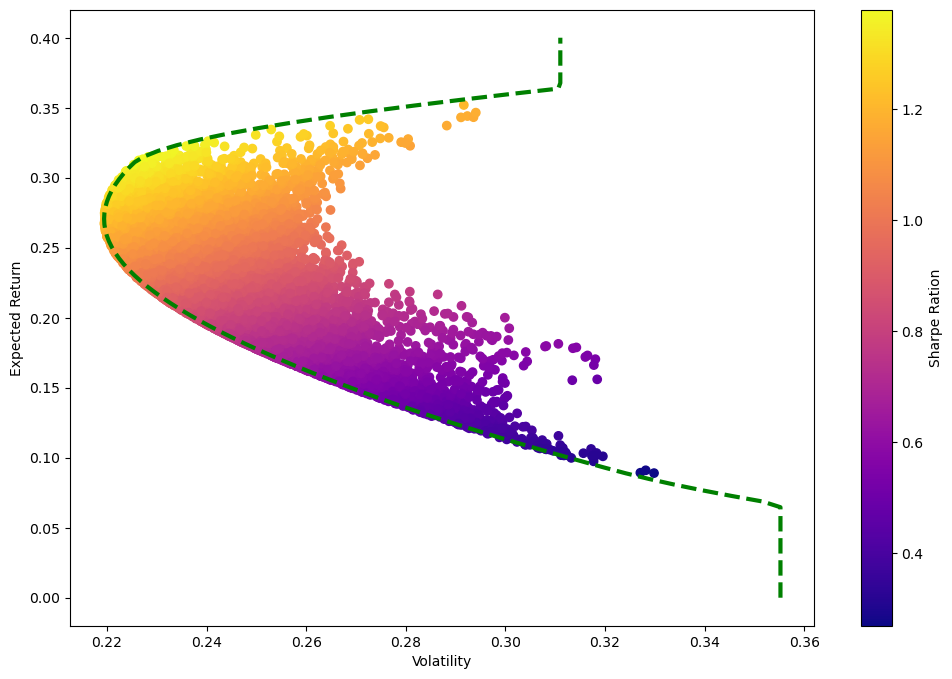

In [ ]:
#
# this is as before..
#
plt.figure(figsize=(12,8))
plt.scatter(vol_array, returns_array, c=sharpe_array, cmap='plasma')
plt.colorbar(label='Sharpe Ration')
plt.xlabel('Volatility')
plt.ylabel('Expected Return')
#
# here we add th frontier volatility
plt.plot(frontier_volatility, frontier_y, 'g--', linewidth=3)
#
# Note that here we don't have the values of the weights..
# if you want them you have to extract them

In [ ]:
#